# CDGCN: Unconditional molecular pretraining (PyTorch)

**Objective:** CDGCN-style negative log-likelihood, `loss = -mean(per_molecule_loglik)` after importance sampling over `K=5` graph traversal paths (`alpha=0.8`). This stage learns a general molecular graph generator **without protein conditioning and without any toxicity labels, weights, or penalties**. Desired properties and protein targets can be introduced in a separate fine-tuning stage.

**Architecture:** Retains the uploaded notebook's graph-convolution/GRU/action-policy architecture and tensor shapes. **This is a PyTorch implementation of CDGCN-style pretraining, not a claim of numerical equivalence to the original MXNet paper**. The uploaded notebook's training hyperparameters (including batch size 32) remain unchanged except for the objective and label-specific validation.

**Output safety:** By default every checkpoint, metadata file, final weight file, log, and plot is written under `REWORKED_CODE/pretraining/pretraining_runs/cdgcn_torch_nll_bs32_v1/`, **alongside**, not inside, `ctddg_torch_eq8_bs32_v1/`. Fresh runs refuse to write into a nonempty run folder; resume only with matching CDGCN metadata. No CTDDG weights or logs are loaded or modified.

**Dataset:** Prefer the unlabelled filtered `chembl.txt`. The parser also accepts the existing `chembl_final.txt` format (`SMILES 0/1`), discarding its label completely. The input is never modified. Ensure the upstream ChEMBL filtering excludes BindingDB ligands before claiming a leakage-free reproduction.


## 1. Imports and paths

In [11]:
import os, json, math, random, time, hashlib
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import networkx as nx
from scipy import sparse
from rdkit import Chem, RDLogger
import rdkit
import torch
from torch import nn
from torch.nn import functional as F
RDLogger.DisableLog('rdApp.warning')
print('PyTorch',torch.__version__,'RDKit',rdkit.__version__,'CUDA available:',torch.cuda.is_available())

PyTorch 2.4.1+cu121 RDKit 2026.03.6 CUDA available: True


In [12]:
# Check HPC input paths before running. No output path points to a CTDDG training directory.
PREPROCESSED_DIR = Path('/home/muhamed/repo/CTDDG/REWORKED_CODE/chembl_preprocessed')
CHEMBL_FILE = PREPROCESSED_DIR / 'chembl.txt'   # preferred: filtered, unlabelled SMILES
if not CHEMBL_FILE.is_file():
    CHEMBL_FILE = PREPROCESSED_DIR / 'chembl_final.txt'  # legacy: label column will be discarded
ATOM_TYPES_FILE = PREPROCESSED_DIR / 'atom_types.txt'

PRETRAIN_RUNS_ROOT = Path('/home/muhamed/repo/CTDDG/REWORKED_CODE/pretraining/pretraining_runs')
CTDDG_RUN_DIR = PRETRAIN_RUNS_ROOT / 'ctddg_torch_eq8_bs32_v1'  # protected; never write here
RUN_DIR = PRETRAIN_RUNS_ROOT / 'cdgcn_torch_nll_bs32_v1'         # separate sibling folder

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 8
K_PATHS = 5
ALPHA = 0.8
EPOCHS = 5  # unchanged from the supplied notebook (not a prescribed paper epoch count)
MAX_STEPS = None  # None = full EPOCHS; positive int = optional debugging limit
MAX_ITER_PER_MOL = 120
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.0
LR_DECAY = 1e-3  # multiply the learning rate by (1-LR_DECAY) every LR_DECAY_STEP
LR_DECAY_STEP = 100
GRAD_CLIP = 3.0
LOG_EVERY = 100
SAVE_EVERY = 500
VAL_FRACTION = 0.05
VAL_SEED = 2026
VAL_MAX_EVAL_MOLECULES = 512
VAL_EVERY = 5000
RESUME = True  # only resume this CDGCN run; never reuse a CTDDG checkpoint

F_E = 16
F_H = [32, 64, 128, 128, 256, 256]
F_SKIP = 256
F_C = [512]
F_POLICY = 128
N_RNN = 3
RECEPTIVE_FIELD = 2

assert BATCH_SIZE >= 2 and K_PATHS >= 1 and 0.0 < ALPHA < 1.0
assert LR_DECAY_STEP >= 1 and SAVE_EVERY >= 1 and EPOCHS >= 1
assert 0 < VAL_FRACTION < 1 and VAL_MAX_EVAL_MOLECULES >= 2 and VAL_EVERY >= 1
# Both equality and nesting are forbidden, even if somebody later edits RUN_DIR.
_output = RUN_DIR.resolve()
_protected = CTDDG_RUN_DIR.resolve()
if _output == _protected or _output in _protected.parents or _protected in _output.parents:
    raise ValueError(f'CDGCN output directory must be separate from CTDDG: {RUN_DIR}')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print('Device:', DEVICE)
print('Input:', CHEMBL_FILE)
print('CDGCN-only outputs:', RUN_DIR)
print('Protected CTDDG folder:', CTDDG_RUN_DIR)


Device: cuda
Input: /home/muhamed/repo/CTDDG/REWORKED_CODE/chembl_preprocessed/chembl.txt
CDGCN-only outputs: /home/muhamed/repo/CTDDG/REWORKED_CODE/pretraining/pretraining_runs/cdgcn_torch_nll_bs32_v1
Protected CTDDG folder: /home/muhamed/repo/CTDDG/REWORKED_CODE/pretraining/pretraining_runs/ctddg_torch_eq8_bs32_v1


## 2. Unlabelled molecular input and exact atom-type vocabulary


In [13]:
class MoleculeSpec:
    def __init__(self, file_name):
        rows = []
        with Path(file_name).open(encoding='utf8') as f:
            for i,line in enumerate(f,1):
                if not line.strip(): continue
                parts = line.strip().split(',')
                if len(parts)!=3: raise ValueError(f'{file_name}:{i}: expected symbol,charge,explicitHs')
                rows.append((parts[0], int(parts[1]), int(parts[2])))
        if not rows or len(rows)!=len(set(rows)):raise ValueError('Empty or duplicated atom vocabulary')
        self.atom_types=rows
        self.atom_index={t:i for i,t in enumerate(rows)}
        self.bond_orders=[Chem.BondType.AROMATIC,Chem.BondType.SINGLE,Chem.BondType.DOUBLE,Chem.BondType.TRIPLE]
        self.bond_index={b:i for i,b in enumerate(self.bond_orders)}
        self.num_atom_types=len(self.atom_types)
        self.num_bond_types=len(self.bond_orders)
        self.max_iter=MAX_ITER_PER_MOL

    def get_atom_type(self, a):
        key=(a.GetSymbol(), a.GetFormalCharge(), a.GetNumExplicitHs())
        if key not in self.atom_index:raise ValueError(f'Out-of-vocabulary atom {key}; check atom_types.txt')
        return self.atom_index[key]

    def get_bond_type(self, b):
        bt=b.GetBondType()
        if bt not in self.bond_index:raise ValueError(f'Unsupported bond {bt}')
        return self.bond_index[bt]

    def index_to_atom(self, idx):
        symbol,charge,hs=self.atom_types[int(idx)]
        atom=Chem.Atom(symbol);atom.SetFormalCharge(charge);atom.SetNumExplicitHs(hs)
        return atom

    def index_to_bond(self, mol, begin_id, end_id, idx):
        mol.AddBond(int(begin_id),int(end_id),self.bond_orders[int(idx)])

_mol_spec=None
def get_mol_spec():
    global _mol_spec
    if _mol_spec is None:_mol_spec=MoleculeSpec(ATOM_TYPES_FILE)
    return _mol_spec

def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for c in iter(lambda:f.read(1<<20),b''):h.update(c)
    return h.hexdigest()

def read_data(path):
    """Read unlabelled SMILES or legacy `SMILES 0/1`; ignore any legacy class column."""
    rows=[]
    with Path(path).open(encoding='utf8') as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip():
                continue
            fields=line.strip().split()
            if len(fields)==1:
                smiles=fields[0]
            elif len(fields)==2 and fields[1] in ('0','1'):
                smiles=fields[0]  # do NOT use the old class in pretraining
            else:
                raise ValueError(f'{path}:{line_no}: expected SMILES or SMILES followed by 0/1')
            rows.append(smiles)
    if not rows:
        raise ValueError('Dataset has no molecules')
    print('Molecules loaded (unlabelled):', len(rows))
    return rows

if not CHEMBL_FILE.is_file():raise FileNotFoundError(CHEMBL_FILE)
if not ATOM_TYPES_FILE.is_file():raise FileNotFoundError(ATOM_TYPES_FILE)
dataset=read_data(CHEMBL_FILE)
print('Atom vocabulary size:',get_mol_spec().num_atom_types)


Molecules loaded (unlabelled): 1158227
Atom vocabulary size: 43


## 3. CDGCN graph-path encoding

The graph traversal and importance-sampling logic are unchanged. Molecules are represented by SMILES only; there are no molecular property labels in this stage.


In [14]:
def get_graph_from_smiles(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        raise ValueError(f'RDKit cannot parse {smiles!r}')
    if mol.GetNumAtoms() < 1:
        raise ValueError(f'No atoms: {smiles!r}')
    # build graph
    atom_types, atom_ranks, bonds, bond_types = [], [], [], []
    for a, r in zip(mol.GetAtoms(), Chem.CanonicalRankAtoms(mol)):
        atom_types.append(get_mol_spec().get_atom_type(a))
        atom_ranks.append(r)
    for b in mol.GetBonds():
        idx_1, idx_2, bt = b.GetBeginAtomIdx(), b.GetEndAtomIdx(), get_mol_spec().get_bond_type(b)
        bonds.append([idx_1, idx_2])
        bond_types.append(bt)

    # build nx graph
    graph = nx.Graph()
    graph.add_nodes_from(range(len(atom_types)))
    graph.add_edges_from(bonds)

    if not nx.is_connected(graph):
        raise ValueError(f'Disconnected fragments: {smiles!r}')
    return graph, atom_types, atom_ranks, bonds, bond_types


def get_graph_from_smiles_list(smiles_list):
    graph_list = []
    for smiles in smiles_list:
        mol = Chem.MolFromSmiles(smiles)

        # build graph
        atom_types, bonds, bond_types = [], [], []
        for a in mol.GetAtoms():
            atom_types.append(get_mol_spec().get_atom_type(a))
        for b in mol.GetBonds():
            idx_1, idx_2, bt = b.GetBeginAtomIdx(), b.GetEndAtomIdx(), get_mol_spec().get_bond_type(b)
            bonds.append([idx_1, idx_2])
            bond_types.append(bt)

        X_0 = np.array(atom_types, dtype=np.int32)
        A_0 = np.concatenate([np.array(bonds, dtype=np.int32),
                              np.array(bond_types, dtype=np.int32)[:, np.newaxis]],
                             axis=1)
        graph_list.append([X_0, A_0])
    return graph_list


def traverse_graph(graph, atom_ranks, current_node=None, step_ids=None, p=0.9, log_p=0.0):
    if current_node is None:
        #print(f"Traversal has started")
        next_nodes = range(len(atom_ranks))
        step_ids = [-1, ] * len(next_nodes)
        next_node_ranks = atom_ranks
    else:
        next_nodes = graph.neighbors(current_node)  # get neighbor nodes
        next_nodes = [n for n in next_nodes if step_ids[n] < 0] # filter visited nodes
        next_node_ranks = [atom_ranks[n] for n in next_nodes] # get ranks for neighbors
    next_nodes = [n for n, r in sorted(zip(next_nodes, next_node_ranks), key=lambda _x:_x[1])] # sort by rank

    # iterate through neighbors
    while len(next_nodes) > 0:
        if len(next_nodes)==1:
            next_node = next_nodes[0]
        elif random.random() >= (1 - p):
            next_node = next_nodes[0]
            log_p += np.log(p)
        else:
            next_node = next_nodes[random.randint(1, len(next_nodes) - 1)]
            log_p += np.log((1.0 - p) / (len(next_nodes) - 1))
        step_ids[next_node] = max(step_ids) + 1
        _, log_p = traverse_graph(graph, atom_ranks, next_node, step_ids, p, log_p)
        next_nodes = [n for n in next_nodes if step_ids[n] < 0] # filter visited nodes


    return step_ids, log_p


def single_reorder(X_0, A_0, step_ids):

    X_0, A_0 = np.copy(X_0), np.copy(A_0)


    # Singleton graphs contain zero bonds: INIT(atom) -> END.
    # Maintain a [0,3] bond array for downstream graph operations.
    if A_0.shape[0] == 0:
        if len(X_0) != 1:
            raise ValueError('A bondless graph must have exactly one atom')
        return X_0, np.empty((0,3), dtype=np.int32)

    step_ids = np.array(step_ids, dtype=np.int32)

    # sort by step_ids
    sorted_ids = np.argsort(step_ids)
    X_0 = X_0[sorted_ids]
    A_0[:, 0], A_0[:, 1] = step_ids[A_0[:, 0]], step_ids[A_0[:, 1]]
    # max_b is the max_index of each bond,min_b is the min index of each index
    max_b, min_b = np.amax(A_0[:, :2], axis=1), np.amin(A_0[:, :2], axis=1)
    A_0 = A_0[np.lexsort([-min_b, max_b]), :]

    # separate append and connect
    max_b, min_b = np.amax(A_0[:, :2], axis=1), np.amin(A_0[:, :2], axis=1)
    is_append = np.concatenate([np.array([True]), max_b[1:] > max_b[:-1]])
    A_0 = np.concatenate([np.where(is_append[:, np.newaxis],
                                 np.stack([min_b, max_b], axis=1),
                                 np.stack([max_b, min_b], axis=1)),
                        A_0[:, -1:]], axis=1)

    return X_0, A_0


def single_expand(X_0, A_0):
    #print(f"We are in single expand function")
    X_0, A_0 = np.copy(X_0), np.copy(A_0)

    # expand X

    is_append_iter = np.less(A_0[:, 0], A_0[:, 1]).astype(np.int32)


    NX = np.cumsum(np.pad(is_append_iter, [[1, 0]], mode='constant', constant_values=1))
    shift = np.cumsum(np.pad(NX, [[1, 0]], mode='constant')[:-1])
    X_index = np.arange(NX.sum(), dtype=np.int32) - np.repeat(shift, NX)


    X = X_0[X_index]

    _, A_index = np.tril_indices(A_0.shape[0])

    A = A_0[A_index, :]

    NA = np.arange(A_0.shape[0] + 1)                  # Num_of_bonds + 1

    action_type = 1 - is_append_iter
    atom_type = np.where(action_type == 0, X_0[A_0[:, 1]], 0)
    bond_type = A_0[:, 2]
    append_pos = np.where(action_type == 0, A_0[:, 0], 0)
    connect_pos = np.where(action_type == 1, A_0[:, 1], 0)
    actions = np.stack([action_type, atom_type, bond_type, append_pos, connect_pos],
                       axis=1)
    last_action = [[2, 0, 0, 0, 0]]
    actions = np.append(actions, last_action, axis=0)
    #print(f"actions is {actions}")
    action_0 = np.array([X_0[0]], dtype=np.int32)
    #print(f"action_0 is {action_0}")


    last_atom_index = shift + NX - 1
    last_atom_mask = np.zeros_like(X)
    last_atom_mask[last_atom_index] = np.where(
        np.pad(is_append_iter, [[1, 0]], mode='constant', constant_values=1) == 1,
        np.ones_like(last_atom_index),
        np.ones_like(last_atom_index) * 2)


    return action_0, X, NX, A, NA, actions, last_atom_mask


def get_d(A, X):

    _to_sparse = lambda _A, _X: sparse.coo_matrix((np.ones([_A.shape[0] * 2], dtype=np.int32),
                                                   (np.concatenate([_A[:, 0], _A[:, 1]], axis=0),
                                                    np.concatenate([_A[:, 1], _A[:, 0]], axis=0))),
                                                    shape=[_X.shape[0], ] * 2)   # this is creating a square matrtix of size len(X)


    A_sparse = _to_sparse(A, X)

    d2 = A_sparse * A_sparse
    d3 = d2 * A_sparse

    D_2 = np.stack(d2.nonzero(), axis=1)
    D_2 = D_2[D_2[:, 0] < D_2[:, 1], :]

    D_3 = np.stack(d3.nonzero(), axis=1)
    D_3 = D_3[D_3[:, 0] < D_3[:, 1], :]

    D_3_sparse = _to_sparse(D_3, X)
    D_3_sparse = D_3_sparse - D_3_sparse.multiply(A_sparse)
    D_3 = np.stack(D_3_sparse.nonzero(), axis=1)
    D_3 = D_3[D_3[:, 0] < D_3[:, 1], :]

    return D_2, D_3


def merge_single_0(X_0, A_0, NX_0, NA_0):

    cumsum = np.cumsum(np.pad(NX_0, [[1, 0]], mode='constant')[:-1])

    A_0[:, :2] += np.stack([np.repeat(cumsum, NA_0), ] * 2, axis=1)

    D_0_2, D_0_3 = get_d(A_0, X_0)

    A_split = []
    for i in range(get_mol_spec().num_bond_types):
        A_i = A_0[A_0[:, 2] == i, :2]
        A_split.append(A_i)
    A_split.extend([D_0_2, D_0_3])
    A_0 = A_split


    NX_rep_0 = np.repeat(np.arange(NX_0.shape[0]), NX_0)


    return X_0, A_0, NX_0, NX_rep_0


def merge_single(X, A, NX, NA, mol_ids, rep_ids, iw_ids, action_0, actions, last_append_mask, log_p):

    X, A, NX, NX_rep = merge_single_0(X, A, NX, NA)
    cumsum = np.cumsum(np.pad(NX, [[1, 0]], mode='constant')[:-1])
    actions[:, -2] += cumsum * (actions[:, 0] == 0)
    actions[:, -1] += cumsum * (actions[:, 0] == 1)
    mol_ids_rep = np.repeat(mol_ids, NX)
    rep_ids_rep = np.repeat(rep_ids, NX)

    return X, A,\
           mol_ids_rep, rep_ids_rep, iw_ids,\
           last_append_mask,\
           NX, NX_rep,\
           action_0, actions, \
           log_p


def process_single(smiles, k, p):
    """Return K importance-sampled graph paths for one unlabelled SMILES molecule."""
    graph, atom_types, atom_ranks, bonds, bond_types = get_graph_from_smiles(smiles)
    if not nx.is_connected(graph):
        raise ValueError(f'Disconnected SMILES (remove salts/fragments first): {smiles}')
    X_0=np.asarray(atom_types,dtype=np.int32)
    A_0=np.column_stack((np.asarray(bonds,dtype=np.int32).reshape(-1,2),
                         np.asarray(bond_types,dtype=np.int32)))
    if len(bonds)+1 > get_mol_spec().max_iter:
        raise ValueError(f'{smiles}: requires {len(bonds)+1} generation steps, max={get_mol_spec().max_iter}')

    X,A,NX,NA=[],[],[],[]
    mol_ids,rep_ids,iw_ids=[],[],[]
    action_0,actions,last_append_mask,log_p=[],[],[],[]
    for path_idx in range(k):
        steps,lp=traverse_graph(graph,atom_ranks,p=p)
        X_i,A_i=single_reorder(X_0,A_0,steps)
        init_i,X_i,NX_i,A_i,NA_i,actions_i,mask_i=single_expand(X_i,A_i)
        X.append(X_i);A.append(A_i);NX.append(NX_i);NA.append(NA_i)
        action_0.append(init_i);actions.append(actions_i);last_append_mask.append(mask_i)
        mol_ids.append(np.zeros_like(NX_i,dtype=np.int32))
        rep_ids.append(np.full_like(NX_i,path_idx,dtype=np.int32))
        iw_ids.append(np.full_like(NX_i,path_idx,dtype=np.int32))
        log_p.append(lp)
    return (np.concatenate(X),np.concatenate(A),np.concatenate(NX),np.concatenate(NA),
            np.concatenate(mol_ids),np.concatenate(rep_ids),np.concatenate(iw_ids),
            np.concatenate(action_0),np.concatenate(actions),np.concatenate(last_append_mask),
            np.asarray(log_p,dtype=np.float32))


def get_mol_from_graph(X, A, sanitize=True):
    try:
        mol = Chem.RWMol(Chem.Mol())

        X, A = X.tolist(), A.tolist()
        for i, atom_type in enumerate(X):
            mol.AddAtom(get_mol_spec().index_to_atom(atom_type))

        for atom_id1, atom_id2, bond_type in A:
            get_mol_spec().index_to_bond(mol, atom_id1, atom_id2, bond_type)
    except:
        return None

    if sanitize:
        try:
            mol = mol.GetMol()
            Chem.SanitizeMol(mol)
            return mol
        except:
            return None
    else:
        return mol


def get_mol_from_graph_list(graph_list, sanitize=True):
    mol_list = [get_mol_from_graph(X, A, sanitize) for X, A in graph_list]
    return mol_list


## 4. Build batches of unlabelled molecular graph paths and GRU indices


In [15]:
def collate_graph_records(records, k=K_PATHS, alpha=ALPHA, device=DEVICE):
    # Reuse original MXNet graph construction and importance-sampled paths.
    fields=[[] for _ in range(11)]
    mol_id_offset, path_id_offset = 0,0
    nsteps_per_molecule=[]
    for i,rec in enumerate(records):
        rec_parts=list(process_single(rec,k,alpha))
        rec_parts[4] += i   # molecule IDs
        rec_parts[6] += i*k # unique path IDs across molecules
        for j,a in enumerate(rec_parts):fields[j].append(a)
        mol=Chem.MolFromSmiles(rec)
        nsteps_per_molecule.append(mol.GetNumBonds()+1)
    X,A,NX,NA,mol_ids,rep_ids,iw_ids,action_0,actions,last_mask,log_p = [
        np.concatenate(col,axis=0) for col in fields
    ]
    X, A, mol_ids_rep,rep_ids_rep,iw_ids,last_mask,NX,NX_rep,action_0,actions,log_p = merge_single(
        X,A,NX,NA,mol_ids,rep_ids,iw_ids,action_0,actions,last_mask,log_p)

    # The original loader has one RNN step for every intermediate graph; graph-to-RNN
    # is [B,K,120] padded with zeros and rnn-to-graph indexes only real steps.
    B=len(records)
    graph_to_rnn=np.zeros([B,k,get_mol_spec().max_iter],dtype=np.int64)
    rnn_to_graph=[]
    curr=0
    for i,steps in enumerate(nsteps_per_molecule):
        if steps>get_mol_spec().max_iter:raise ValueError(f'Graph requires {steps} steps; max={get_mol_spec().max_iter}')
        for path in range(k):
            graph_to_rnn[i,path,:steps]=np.arange(steps)+curr
            rnn_to_graph += [(i,path,t) for t in range(steps)]
            curr += steps
    assert curr==len(NX)
    rnn_to_graph=np.asarray(rnn_to_graph,dtype=np.int64)
    edges=[]
    for adj in A:
        if len(adj)==0:
            edges.append(torch.empty((2,0),dtype=torch.long,device=device))
        else:
            both=np.concatenate([adj[:,0:2],adj[:,[1,0]]],axis=0)
            edges.append(torch.as_tensor(both.T.copy(),dtype=torch.long,device=device))
    batch={
      'X':torch.as_tensor(X.astype(np.int64),device=device),
      'edges':edges,
      'iw_ids':torch.as_tensor(iw_ids.astype(np.int64),device=device),
      'last_mask':torch.as_tensor(last_mask.astype(np.int64),device=device),
      'NX':torch.as_tensor(NX.astype(np.int64),device=device),
      'NX_rep':torch.as_tensor(NX_rep.astype(np.int64),device=device),
      'action_0':torch.as_tensor(action_0.astype(np.int64),device=device),
      'actions':torch.as_tensor(actions.astype(np.int64),device=device),
      'log_p_sigma':torch.as_tensor(log_p.astype(np.float32),device=device),
      'graph_to_rnn':torch.as_tensor(graph_to_rnn,device=device),
      'rnn_to_graph':torch.as_tensor(rnn_to_graph,device=device),
      'NX_cum':torch.as_tensor(np.cumsum(NX),dtype=torch.long,device=device),
      'batch_size':B, 'iw_size':k,
    }
    assert batch['log_p_sigma'].shape==(B*k,)
    assert batch['action_0'].shape==(B*k,)
    assert batch['actions'].shape[0]==batch['NX'].shape[0]
    return batch

def make_batches(rows, epoch, batch_size=BATCH_SIZE, seed=SEED):
    # Length-bucketed sampler as in original CDGCN (limits memory for variable graph sizes).
    # Fully reproducible batch order for each epoch; final <B records are dropped to match original.
    indices=np.argsort([len(x) for x in rows]).tolist()
    n=len(indices)//batch_size
    if n==0:raise ValueError('Need at least batch_size molecules')
    rng=random.Random(seed+epoch)
    buckets=[indices[i*n:(i+1)*n] for i in range(batch_size)]
    for bucket in buckets:rng.shuffle(bucket)
    batches=[tuple(z) for z in zip(*buckets)]
    rng.shuffle(batches)
    return batches


## 5. CDGCN graph convolutions, GRU, and action policy


In [16]:
def sum_segments(x, seg_id, count):
    result=x.new_zeros((count,)+x.shape[1:])
    return result.index_add(0,seg_id,x)

class LinearBN(nn.Module):
    def __init__(self, fin, fout):
        super().__init__()
        self.linear=nn.Linear(fin,fout,bias=False)
        self.bn=nn.BatchNorm1d(fout)
    def forward(self,x):return self.bn(self.linear(x))

class GraphConv(nn.Module):
    """CDGCN GC with one self term + one matrix per bond/distance relation."""
    def __init__(self, fin, fout, n_relations):
        super().__init__()
        self.W=nn.Parameter(torch.empty(fin*(1+n_relations),fout))
        nn.init.xavier_uniform_(self.W)
        self.n_relations=n_relations

    def forward(self,X,edge_lists):
        assert len(edge_lists)==self.n_relations
        terms=[X]
        for edge in edge_lists:
            if edge.numel()==0:terms.append(torch.zeros_like(X))
            else:
                terms.append(sum_segments(X[edge[1]],edge[0],X.shape[0]))
        return torch.cat(terms,dim=-1) @ self.W

class GraphBackbone(nn.Module):
    def __init__(self,n_atom,n_bond,D,F_e,F_h,F_skip,F_c):
        super().__init__()
        self.atom_embedding=nn.Embedding(n_atom,F_e)
        self.mask_embedding=nn.Embedding(3,F_e)
        self.convs=nn.ModuleList()
        self.pre_bns=nn.ModuleList()
        for i,fout in enumerate(F_h):
            fin=F_e if i==0 else F_h[i-1]
            self.pre_bns.append(nn.Identity() if i==0 else nn.BatchNorm1d(fin))
            self.convs.append(GraphConv(fin,fout,n_bond+D))
        self.bn_skip=nn.BatchNorm1d(sum(F_h))
        self.skip=LinearBN(sum(F_h),F_skip)
        self.dense=nn.ModuleList()
        for fin,fout in zip([F_skip]+F_c[:-1],F_c):self.dense.append(LinearBN(fin,fout))

    def forward(self,b):
        X=self.atom_embedding(b['X'])+self.mask_embedding(b['last_mask'])
        layer_out=[]
        for conv,bn in zip(self.convs,self.pre_bns):
            X=conv(F.relu(bn(X)) if not isinstance(bn,nn.Identity) else X,b['edges'])
            layer_out.append(X)
        X=F.relu(self.skip(F.relu(self.bn_skip(torch.cat(layer_out,dim=-1)))))
        for dense in self.dense:X=dense(X)
        return X

class Policy(nn.Module):
    def __init__(self,fin,hidden,n_atom,n_bond):
        super().__init__()
        self.n_atom=n_atom;self.n_bond=n_bond
        self.linear_h=LinearBN(fin*2,hidden)
        self.linear_h_t=LinearBN(fin,hidden)
        self.linear_x=nn.Linear(hidden,n_bond*(n_atom+1))
        self.linear_x_t=nn.Linear(hidden,1)

    def forward(self,X,b,X_end):
        nx_rep=b['NX_rep'];n_step=b['NX'].shape[0]
        node_state=torch.cat([X,X_end[nx_rep]],dim=-1)
        node_logits=self.linear_x(F.relu(self.linear_h(node_state)))
        end_logits=self.linear_x_t(F.relu(self.linear_h_t(X_end)))
        # Stable per-graph softmax over every (node, append/connect action) AND end.
        per_node_max=node_logits.max(dim=-1).values
        group_max=end_logits[:,0].clone()
        group_max=group_max.scatter_reduce(0,nx_rep,per_node_max,reduce='amax',include_self=True)
        node_weight=torch.exp(node_logits-group_max[nx_rep,None])
        end_weight=torch.exp(end_logits-group_max[:,None])
        denom=sum_segments(node_weight.sum(-1,keepdim=True),nx_rep,n_step)+end_weight
        soft_node=node_weight/denom[nx_rep]
        soft_end=(end_weight/denom)[:,0]
        connect=soft_node[:,:self.n_bond]
        append=soft_node[:,self.n_bond:].reshape(-1,self.n_atom,self.n_bond)
        return append,connect,soft_end

class CDGCNPretrainer(nn.Module):
    def __init__(self,n_atom,n_bond,D=2,F_e=16,F_h=(32,64,128,128,256,256),
                 F_skip=256,F_c=(512,),F_policy=128,n_rnn=3):
        super().__init__()
        self.n_atom=n_atom;self.n_bond=n_bond
        self.backbone=GraphBackbone(n_atom,n_bond,D,F_e,list(F_h),F_skip,list(F_c))
        self.rnn=nn.GRU(input_size=2*F_c[-1],hidden_size=F_c[-1],num_layers=n_rnn,batch_first=True)
        self.policy=Policy(F_c[-1],F_policy,n_atom,n_bond)
        self.init_atom_logits=nn.Parameter(torch.zeros(n_atom))
        # Original MXNet notebook initializes trainable matrices with Xavier.
        # Match that policy rather than PyTorch's default Kaiming/embedding init.
        for module in self.modules():
            if isinstance(module,(nn.Linear,nn.Embedding)):
                nn.init.xavier_uniform_(module.weight)
                if getattr(module,'bias',None) is not None:nn.init.zeros_(module.bias)
            elif isinstance(module,nn.GRU):
                for name,param in module.named_parameters():
                    if 'weight' in name:nn.init.xavier_uniform_(param)
                    elif 'bias' in name:nn.init.zeros_(param)
            elif isinstance(module,nn.BatchNorm1d):
                nn.init.ones_(module.weight);nn.init.zeros_(module.bias)

    def per_molecule_loglik(self,b):
        B,K=b['batch_size'],b['iw_size']
        X=self.backbone(b)
        n_step=b['NX'].numel()
        X_avg=sum_segments(X,b['NX_rep'],n_step)/b['NX'][:,None].to(X.dtype)
        X_last=X[b['NX_cum']-1]
        features=torch.cat([X_avg,X_last],dim=-1)
        # Padded sequences; gathering only actual step outputs means padding cannot change valid outputs.
        padded=features[b['graph_to_rnn']].reshape(B*K,-1,features.shape[-1])
        rnn_out,_=self.rnn(padded)
        rnn_out=rnn_out.reshape(B,K,-1,rnn_out.shape[-1])
        idx=b['rnn_to_graph']
        X_end=rnn_out[idx[:,0],idx[:,1],idx[:,2]]
        append,connect,end=self.policy(X,b,X_end)
        act=b['actions'];act_type=act[:,0]
        eps=1e-10
        init_logprob=F.log_softmax(self.init_atom_logits,dim=0)
        init_ll=init_logprob[b['action_0']]
        # indices in actions refer to global offset into concatenated graph nodes
        append_log=torch.log(append[act[:,3],act[:,1],act[:,2]]+eps)
        connect_log=torch.log(connect[act[:,4],act[:,2]]+eps)
        end_log=torch.log(end+eps)
        action_ll=torch.where(act_type==0,append_log,torch.where(act_type==1,connect_log,end_log))
        path_ll=sum_segments(action_ll[:,None],b['iw_ids'],B*K)[:,0] + init_ll
        path_ll=path_ll.reshape(B,K)-b['log_p_sigma'].reshape(B,K)
        return torch.logsumexp(path_ll,dim=1)-math.log(K)

def cdgcn_nll(ll):
    """Unconditional CDGCN loss: negative mean importance-sampled graph log-likelihood."""
    if ll.ndim != 1 or not ll.numel():
        raise ValueError(f'Expected nonempty per-molecule likelihood vector [B], got {ll.shape}')
    return -ll.mean()


## 6. Unit tests — plain NLL, graph invariants, gradients


In [17]:
# Mathematical test: every molecule receives the same negative-log-likelihood objective.
values=torch.tensor([-2.,-3.],requires_grad=True)
loss_test=cdgcn_nll(values)
assert torch.allclose(loss_test,torch.tensor(2.5))
loss_test.backward()
assert torch.allclose(values.grad,torch.tensor([-0.5,-0.5]))
print('PASS unconditional NLL signs and gradients')

# Pick two real unlabelled records and verify graph-path collation.
if len(dataset)<2:raise ValueError('Need two molecules for batch tests')
row0,row1=dataset[0],dataset[1]
for rec in (row0,row1):
    out=process_single(rec,K_PATHS,ALPHA)
    assert len(out)==11 and out[-1].shape==(K_PATHS,)
b=collate_graph_records([row0,row1],device=DEVICE)
assert 'tox_class' not in b
assert b['log_p_sigma'].numel()==2*K_PATHS
assert len(b['edges'])==get_mol_spec().num_bond_types+RECEPTIVE_FIELD
# Action probabilities across append/connect/end must add up to 1 for each intermediate graph.
_test_pol=Policy(12,8,get_mol_spec().num_atom_types,get_mol_spec().num_bond_types).to(DEVICE)
_test_pol.train()
with torch.no_grad():
    _app,_con,_end=_test_pol(torch.randn(b['X'].numel(),12,device=DEVICE),b,
                            torch.randn(b['NX'].numel(),12,device=DEVICE))
    _sum=sum_segments((_app.sum((1,2))+_con.sum(1))[:,None],b['NX_rep'],b['NX'].numel())[:,0]+_end
    assert torch.allclose(_sum,torch.ones_like(_sum),atol=2e-5),_sum
print('PASS action probabilities sum to 1 and unlabelled path encoding')

# Full model forward/backward: small architecture for a cheap smoke test.
small=CDGCNPretrainer(get_mol_spec().num_atom_types,get_mol_spec().num_bond_types,
                     F_h=(16,16),F_c=(32,),F_skip=24,F_policy=16,n_rnn=1).to(DEVICE)
small.train(); ll=small.per_molecule_loglik(b)
assert ll.shape==(2,)
loss=cdgcn_nll(ll)
assert torch.isfinite(loss)
loss.backward()
assert any(p.grad is not None and p.grad.abs().sum().item()>0 for p in small.parameters())
print('PASS full network forward/backward. NLL:',loss.item(),'LL:',ll.detach().tolist())
del small,b,loss,ll


PASS unconditional NLL signs and gradients
PASS action probabilities sum to 1 and unlabelled path encoding
PASS full network forward/backward. NLL: 199.47528076171875 LL: [-208.50213623046875, -190.4484100341797]


## 7. Create the original-width model, optimizer, and isolated CDGCN outputs


## 7. Random ChEMBL train/validation split

Deterministic molecule-level holdout (no class stratification). A small, fixed subset of held-out SMILES is evaluated with identical traversal RNG at each checkpoint. **This is an NLL diagnostic, not a substitute for generating and evaluating molecules.**


In [18]:
# Deterministic unlabelled molecule-level holdout; kept out of optimizer updates.
def split_records(rows, fraction, seed):
    ids=list(range(len(rows)))
    rng=random.Random(seed);rng.shuffle(ids)
    n_val=max(2,min(len(ids)-BATCH_SIZE,round(fraction*len(ids))))
    if n_val<2 or len(ids)-n_val<BATCH_SIZE:
        raise ValueError('Need enough molecules for validation and at least one training batch')
    val_set=set(ids[:n_val])
    train_rows=[row for i,row in enumerate(rows) if i not in val_set]
    holdout_rows=[row for i,row in enumerate(rows) if i in val_set]
    return train_rows,holdout_rows

def fixed_eval_subset(rows,max_records,seed):
    if len(rows)<=max_records:return list(rows)
    rng=random.Random(seed)
    return [rows[i] for i in sorted(rng.sample(range(len(rows)),max_records))]

train_dataset,val_dataset=split_records(dataset,VAL_FRACTION,VAL_SEED)
val_eval_dataset=fixed_eval_subset(val_dataset,VAL_MAX_EVAL_MOLECULES,VAL_SEED+1)
val_eval_dataset=sorted(val_eval_dataset,key=len)
assert set(train_dataset).isdisjoint(val_dataset),'Same SMILES in training and validation'
print('Train:',len(train_dataset),'Validation holdout:',len(val_dataset),
      'Fixed evaluation subset:',len(val_eval_dataset))


Train: 1100316 Validation holdout: 57911 Fixed evaluation subset: 512


In [19]:
MODEL_CONFIG={'n_atom':get_mol_spec().num_atom_types,'n_bond':get_mol_spec().num_bond_types,
              'D':RECEPTIVE_FIELD,'F_e':F_E,'F_h':F_H,'F_skip':F_SKIP,'F_c':F_C,
              'F_policy':F_POLICY,'n_rnn':N_RNN}
metadata={'schema_version':2,'model':'CDGCN-unconditional-PyTorch',
          'objective':'negative_mean_importance_sampled_log_likelihood',
          'model_config':MODEL_CONFIG,'k_paths':K_PATHS,'alpha':ALPHA,'batch_size':BATCH_SIZE,
          'seed':SEED,'chembl_sha256':file_hash(CHEMBL_FILE),
          'atom_types_sha256':file_hash(ATOM_TYPES_FILE),
          'n_records':len(dataset),
          'train_records':len(train_dataset),'val_records':len(val_dataset),
          'val_fraction':VAL_FRACTION,'val_seed':VAL_SEED,
          'val_max_eval_molecules':VAL_MAX_EVAL_MOLECULES,
          'max_iter_per_molecule':MAX_ITER_PER_MOL,
          'learning_rate':LEARNING_RATE,'lr_decay':LR_DECAY,
          'lr_decay_step':LR_DECAY_STEP,'grad_clip':GRAD_CLIP,
          'weight_decay':WEIGHT_DECAY}
# Output protection runs BEFORE any file is written.
_output=RUN_DIR.resolve();_protected=CTDDG_RUN_DIR.resolve()
if _output==_protected or _output in _protected.parents or _protected in _output.parents:
    raise ValueError('Refusing to write CDGCN artifacts in or above the CTDDG run folder')
if RUN_DIR.exists() and any(RUN_DIR.iterdir()) and not RESUME:
    raise FileExistsError(f'CDGCN run directory is not empty: {RUN_DIR}. Set RESUME=True or choose a new RUN_DIR.')
if RESUME and not RUN_DIR.is_dir():
    raise FileNotFoundError(f'Cannot resume: CDGCN run directory does not exist: {RUN_DIR}')
RUN_DIR.mkdir(parents=True,exist_ok=True)
ckpt_path=RUN_DIR/'checkpoint.pt'        # model + optimizer + RNG, for restarting training
final_weights_path=RUN_DIR/'model_weights_final.pt'  # model state_dict only, for downstream use
config_path=RUN_DIR/'model_config.json'
meta_path=RUN_DIR/'run_meta.json'
log_path=RUN_DIR/'train_log.jsonl'
val_log_path=RUN_DIR/'validation_log.jsonl'
plot_path=RUN_DIR/'nll_curves.png'
model=CDGCNPretrainer(**MODEL_CONFIG).to(DEVICE)
opt=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
steps_per_epoch=len(train_dataset)//BATCH_SIZE
if not steps_per_epoch:raise ValueError('Insufficient training samples for a batch')
planned_steps=EPOCHS*steps_per_epoch
if MAX_STEPS is not None:planned_steps=min(planned_steps,int(MAX_STEPS))
start_step=0
if RESUME:
    if not ckpt_path.is_file() or not meta_path.is_file():
        raise FileNotFoundError('CDGCN checkpoint / metadata missing')
    prior=json.loads(meta_path.read_text())
    if prior!=metadata:raise ValueError('CDGCN run metadata mismatch; refusing unsafe resume')
    ckpt=torch.load(ckpt_path,map_location='cpu',weights_only=False)  # TRUSTED local checkpoint only
    if ckpt.get('objective')!='cdgcn_nll':
        raise ValueError('Refusing to resume non-CDGCN checkpoint')
    model.load_state_dict(ckpt['model']);opt.load_state_dict(ckpt['optimizer'])
    start_step=ckpt['step']
    random.setstate(ckpt['py_rng']);np.random.set_state(ckpt['np_rng'])
    torch.set_rng_state(ckpt['torch_rng'])
    if DEVICE.type=='cuda' and ckpt.get('cuda_rng') is not None:
        torch.cuda.set_rng_state_all(ckpt['cuda_rng'])
    print('Resumed CDGCN from step',start_step)
else:
    meta_path.write_text(json.dumps(metadata,indent=2))
    config_path.write_text(json.dumps(MODEL_CONFIG,indent=2))
assert start_step<planned_steps, f'Already completed {start_step} / {planned_steps} steps'
print('Model parameters:',sum(p.numel() for p in model.parameters()))
print('Steps per epoch:',steps_per_epoch,'requested steps:',planned_steps)
print('Resume checkpoint:',ckpt_path)
print('Final model weights:',final_weights_path)


Resumed CDGCN from step 687695


AssertionError: Already completed 687695 / 687695 steps

## 8. Train, validate, and save checkpoints

The optimizer minimizes the **unweighted negative log-likelihood** of every molecule. Validation uses the same loss on a fixed held-out subset, with gradients off. All logs, checkpoints, and final weights go exclusively into `RUN_DIR`.

`checkpoint.pt` includes optimizer and RNG states to resume. `model_weights_final.pt` contains the final network's standalone `state_dict` (suitable for loading into the same PyTorch architecture). No CTDDG checkpoint is loaded or overwritten. Run the final cell to save the NLL curves.


In [ ]:
def save_checkpoint(step):
    snap={
        'step':step,'objective':'cdgcn_nll',
        'model':model.state_dict(),'optimizer':opt.state_dict(),
        'py_rng':random.getstate(),'np_rng':np.random.get_state(),
        'torch_rng':torch.get_rng_state(),
        'cuda_rng':torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else None,
    }
    temp=ckpt_path.with_name('checkpoint.tmp.pt')
    torch.save(snap,temp);os.replace(temp,ckpt_path)

def save_final_weights(step):
    """A standalone state_dict for subsequent CDGCN-style conditional fine-tuning."""
    temp=final_weights_path.with_name('model_weights_final.tmp.pt')
    torch.save(model.state_dict(),temp)
    os.replace(temp,final_weights_path)
    print(f'Saved CDGCN final model weights at step {step}: {final_weights_path}')

@torch.no_grad()
def evaluate_validation(step):
    # Fix the path RNG across evaluations without changing training-path sampling.
    rng_state=random.getstate()
    was_training=model.training
    total_loss=0.0;n_total=0
    try:
        model.eval()
        random.seed(VAL_SEED+12345)
        for off in range(0,len(val_eval_dataset),BATCH_SIZE):
            rows=val_eval_dataset[off:off+BATCH_SIZE]
            batch=collate_graph_records(rows,device=DEVICE)
            ll=model.per_molecule_loglik(batch)
            loss=cdgcn_nll(ll)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Nonfinite validation NLL at step {step}')
            size=len(rows)
            total_loss+=float(loss.item())*size
            n_total+=size
    finally:
        random.setstate(rng_state)
        model.train(was_training)
    metrics={'step':step,'val_nll':total_loss/n_total,'n_val_molecules':n_total}
    with val_log_path.open('a') as f:f.write(json.dumps(metrics)+'\n')
    print('VALIDATION:',metrics)
    return metrics

def train(preflight_max_steps=None):
    global start_step
    model.train()
    target=planned_steps if preflight_max_steps is None else min(planned_steps,start_step+preflight_max_steps)
    tic=time.time();loss_sum=0.0;n_in_window=0
    for epoch in range(start_step//steps_per_epoch,EPOCHS):
        idx_batches=make_batches(train_dataset,epoch)
        skip=start_step%steps_per_epoch if epoch==start_step//steps_per_epoch else 0
        for batch_idx in range(skip,len(idx_batches)):
            if start_step>=target:break
            records=[train_dataset[j] for j in idx_batches[batch_idx]]
            batch=collate_graph_records(records,device=DEVICE)
            opt.zero_grad(set_to_none=True)
            ll=model.per_molecule_loglik(batch)
            loss=cdgcn_nll(ll)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Nonfinite training NLL at step {start_step+1}: {loss.item()}')
            loss.backward()
            grad_norm=torch.nn.utils.clip_grad_norm_(model.parameters(),float('inf'),error_if_nonfinite=True)
            torch.nn.utils.clip_grad_value_(model.parameters(),GRAD_CLIP)
            opt.step()
            start_step+=1
            loss_sum+=float(loss.item());n_in_window+=1
            if start_step%LR_DECAY_STEP==0:
                for group in opt.param_groups:group['lr']*=1.0-LR_DECAY
            if start_step==1 or start_step%LOG_EVERY==0 or start_step==target:
                record={'step':start_step,'epoch_equiv':start_step/steps_per_epoch,
                        'elapsed_minutes':round((time.time()-tic)/60,2),
                        'train_nll':float(loss.item()),
                        'train_nll_window_mean':loss_sum/n_in_window,
                        'gradient_norm':float(grad_norm.item()),
                        'mean_graph_loglik':float(ll.detach().mean().item()),
                        'learning_rate':opt.param_groups[0]['lr']}
                with log_path.open('a') as f:f.write(json.dumps(record)+'\n')
                print('TRAIN:',record)
                loss_sum=0.0;n_in_window=0
            if start_step%VAL_EVERY==0 or start_step==target:
                evaluate_validation(start_step)
            if start_step%SAVE_EVERY==0 or start_step==target:
                save_checkpoint(start_step)
        if start_step>=target:break
    if start_step==planned_steps:
        save_final_weights(start_step)
    return start_step

# For a 2-step trial first, use train(preflight_max_steps=2) in a NEW output folder.
# Full pretraining run:
train()


TRAIN: {'step': 106100, 'epoch_equiv': 0.7714175615643563, 'elapsed_minutes': 174.54, 'train_nll': 21.67498779296875, 'train_nll_window_mean': 20.627688341140747, 'gradient_norm': 22.118494033813477, 'mean_graph_loglik': -21.67498779296875, 'learning_rate': 0.00034592584284540644}
TRAIN: {'step': 106200, 'epoch_equiv': 0.7721446280691295, 'elapsed_minutes': 174.7, 'train_nll': 22.99517059326172, 'train_nll_window_mean': 20.427444343566894, 'gradient_norm': 22.57094955444336, 'mean_graph_loglik': -22.99517059326172, 'learning_rate': 0.00034557991700256106}
TRAIN: {'step': 106300, 'epoch_equiv': 0.7728716945739027, 'elapsed_minutes': 174.86, 'train_nll': 19.189111709594727, 'train_nll_window_mean': 20.248076810836793, 'gradient_norm': 22.61588478088379, 'mean_graph_loglik': -19.189111709594727, 'learning_rate': 0.0003452343370855585}
TRAIN: {'step': 106400, 'epoch_equiv': 0.7735987610786759, 'elapsed_minutes': 175.03, 'train_nll': 19.664228439331055, 'train_nll_window_mean': 20.262855520

## 9. Training and validation NLL curves


Saved NLL plot: /home/muhamed/repo/CTDDG/REWORKED_CODE/pretraining/pretraining_runs/cdgcn_torch_nll_bs32_v1/nll_curves.png


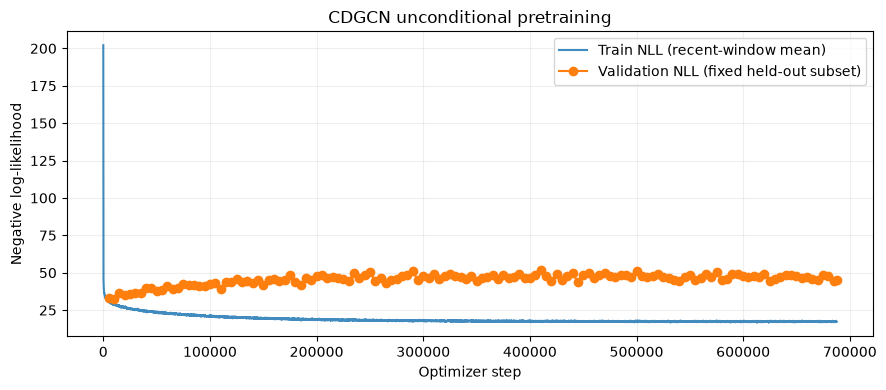

In [21]:
# Safe to rerun after training; reads only from this CDGCN run directory.
import matplotlib.pyplot as plt

def read_jsonl(path):
    if not path.exists():return []
    with path.open() as f:return [json.loads(line) for line in f if line.strip()]

train_hist=read_jsonl(log_path)
val_hist=read_jsonl(val_log_path)
fig,ax=plt.subplots(figsize=(9,4))
if train_hist:
    ax.plot([r['step'] for r in train_hist],
            [r['train_nll_window_mean'] for r in train_hist],label='Train NLL (recent-window mean)',alpha=.85)
if val_hist:
    ax.plot([r['step'] for r in val_hist],
            [r['val_nll'] for r in val_hist],label='Validation NLL (fixed held-out subset)',marker='o')
ax.set(xlabel='Optimizer step',ylabel='Negative log-likelihood',title='CDGCN unconditional pretraining')
ax.legend();ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(plot_path,dpi=160)
print('Saved NLL plot:',plot_path)
plt.show()


## 10. What this notebook does and does not establish

- **Pretraining loss:** CDGCN-style unconditional negative log-likelihood, `-mean(ll)`, with the existing `K=5` importance-sampled paths and `alpha=0.8`; all molecules contribute equally.
- **Removed entirely from pretraining:** Ames labels, toxicity weights, signed Equation 8 loss, toxicity-based data splitting, and per-class validation/training logs. An optional legacy `SMILES 0/1` input column is ignored, never used.
- **Files written:** `checkpoint.pt` (training + optimizer state), `model_weights_final.pt` (state dict), `model_config.json`, `run_meta.json`, `train_log.jsonl`, `validation_log.jsonl`, and `nll_curves.png` — all in a CDGCN-only sibling folder.
- **Downstream fine-tuning:** protein conditioning and the CTDDG toxicity objective can be introduced later with a compatible **conditional PyTorch** implementation. This notebook itself never introduces either.
- **Reproduction limits:** the supplied batch size is **32**, whereas the CDGCN paper used **8**; the notebook has its own train/validation split and is not guaranteed numerically or checkpoint-format equivalent to upstream MXNet. Confirm the ChEMBL ligand-exclusion provenance and validate molecule generation before claiming a paper reproduction.
